# 1. Imports

In [1]:
import os
import random
import sys
import platform

# Torch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
import pytorch_msssim
from pytorch_msssim import ssim
import math
from torchvision import models
from torchvision import datasets, transforms, utils
from torch.utils.data import Dataset, DataLoader, random_split, Subset
from torchvision.utils import make_grid
import torchvision.transforms as transforms

# Image imports
import PIL
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import cv2
from skimage.filters import gaussian
from skimage.util import random_noise

# Sklearn imports
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.decomposition import KernelPCA
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from scipy.spatial import procrustes
from sklearn.preprocessing import StandardScaler,  normalize
from scipy.stats import wasserstein_distance
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

# Dynamic Plotting imports
# import plotly.express as px
import base64
import io
import seaborn as sns
from matplotlib.offsetbox import OffsetImage, AnnotationBbox


# 2-Point Correlations Imports
from skimage.util import view_as_blocks
from skimage import io as skio, color
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from numpy.fft import fft2, ifft2, fftshift
from scipy import ndimage
import imageio

# tqdm
from tqdm.auto import tqdm

# Data loading and saving
import pickle

In [2]:
print("==== SYSTEM INFO ====")
print("OS:", platform.platform())
print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Working directory:", os.getcwd())

print("==== GPU / CUDA INFO ====")
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version (torch):", torch.version.cuda)
print("cuDNN version:", torch.backends.cudnn.version())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

print("\n==== TORCH STACK ====")
print("Torch:", torch.__version__)
print("Torch CUDA:", torch.version.cuda)
print("cuDNN:", torch.backends.cudnn.version())
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

==== SYSTEM INFO ====
OS: Windows-10-10.0.19045-SP0
Python version: 3.9.23 (main, Jun  5 2025, 13:25:08) [MSC v.1929 64 bit (AMD64)]
Python executable: C:\Users\Taha\anaconda3\envs\noise_sens_analysis\python.exe
Working directory: C:\Users\Taha\Desktop\Noise Sensitivity Analysis Notebook
==== GPU / CUDA INFO ====
Torch version: 2.5.1
CUDA available: True
CUDA version (torch): 11.8
cuDNN version: 90100
GPU name: NVIDIA GeForce RTX 2070

==== TORCH STACK ====
Torch: 2.5.1
Torch CUDA: 11.8
cuDNN: 90100
CUDA available: True
GPU: NVIDIA GeForce RTX 2070


# 2. Image Dataset Loading

In [ ]:
# ==========================================
# Data Loading
# ==========================================

# ==============================================================================
# USER CONFIGURATION: Set image directory
# 1. Replace the string below with the absolute path to your folder of 100 images.
# 2. Keep the 'r' before the quotes (raw string) so backslashes don't break on Windows.
# ==============================================================================
folder_path = r"C:\path\to\your\image_folder"

# List all files in the directory
filenames = [f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))]

# Read each file as bytes and create the (filename, bytes) tuples
input_data = []
for fname in filenames:
    full_path = os.path.join(folder_path, fname)
    with open(full_path, 'rb') as file:
        file_bytes = file.read()
        input_data.append((fname, file_bytes))

print(f"Loaded {len(input_data)} files from {folder_path}")


# ==========================================
# Random Seed Configuration
# ==========================================

def set_seed(seed=42):
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    print(f"Random seed set to: {seed}")

set_seed(42)


# ==========================================
# Sampling and Preprocessing Functions
# ==========================================

def sample_subsets(input_data):
    n_total = len(input_data)

    subset_100 = random.sample(input_data, min(100, n_total))
    subset_50  = subset_100[:min(50, len(subset_100))]
    subset_25  = subset_100[:min(25, len(subset_100))]
    subset_10  = subset_100[:min(10, len(subset_100))]

    return subset_100, subset_50, subset_25, subset_10

subset_100, subset_50, subset_25, subset_10 = sample_subsets(input_data)

def image_normalizer(image, tol=1e-6):
    """
    Normalize image to [0,1]. If uniform image with min == max:
    - If the value is already in [0,1], return as is.
    - Otherwise, return a zero image of same shape.
    """
    image_min = image.min()
    image_max = image.max()

    if abs(image_max - image_min) < tol:
        # Uniform image case
        if 0.0 <= image_min <= 1.0:
            return image  # Already normalized uniform image
        else:
            # Uniform but outside [0,1], return zeros to avoid NaNs
            return np.zeros_like(image)
    else:
        return (image - image_min) / (image_max - image_min)

def preprocess_image_base(content_bytes, target_size=512):
    """
    Canonical preprocessing for all methods.

    Output:
        np.ndarray, shape (512, 512), dtype float32, values in [0,1]
    """

    # Load image
    image = Image.open(io.BytesIO(content_bytes)).convert('L')  # grayscale

    w, h = image.size

    # --- Crop from bottom if height > target_size ---
    if h > target_size:
        image = image.crop((0, 0, w, target_size))

    # --- Resize to target_size x target_size ---
    if image.size != (target_size, target_size):
        image = image.resize((target_size, target_size), Image.BILINEAR)

    # Convert to numpy float32
    img_np = np.array(image, dtype=np.float32)

    # Normalize to [0,1]
    img_np = image_normalizer(img_np)

    return img_np

def preprocess_dataset(images):
    """
    images: list of (filename, bytes)
    returns: list of np.ndarray (512,512) float32 in [0,1]
    """
    processed = []

    for filename, content_bytes in images:
        try:
            img = preprocess_image_base(content_bytes)
            processed.append(img)
        except Exception as e:
            print(f"Skipping {filename}: {e}")

    return processed


# ==========================================
# Dataset Preparation
# ==========================================

# Preparing the images
subset_100_proc = preprocess_dataset(subset_100) 
subset_50_proc = preprocess_dataset(subset_50)
subset_25_proc = preprocess_dataset(subset_25)
subset_10_proc = preprocess_dataset(subset_10)

# ==========================================
# Data Processing Check
# ==========================================

def inspect_processed_data(data_list, name="Dataset"):
    print(f"--- Inspection for: {name} ---")

    # 1. Check the outer structure
    outer_type = type(data_list)
    num_items = len(data_list)
    print(f"Outer Structure: {outer_type}")
    print(f"Number of Items: {num_items}")

    if num_items > 0:
        # 2. Check the internal structure (using the first item as a sample)
        sample_img = data_list[0]
        print(f"Internal Item Type: {type(sample_img)}")
        print(f"Array Shape: {sample_img.shape}")
        print(f"Data Type: {sample_img.dtype}")

        # 3. Check normalization values
        print(f"Value Range: [{sample_img.min():.4f}, {sample_img.max():.4f}]")

        # 4. Consistency Check (Verify all images have the same shape)
        shapes = set(img.shape for img in data_list)
        print(f"Uniform Shapes: {'Yes' if len(shapes) == 1 else 'No (Mismatch found!)'}")
    else:
        print("Warning: The list is empty. Check your upload/preprocessing logic.")
    print("-" * 30 + "\n")

# Run the checks
inspect_processed_data(subset_50_proc, "subset_50_proc")


# ==========================================
# Adapting Input for SAM
# ==========================================

def sam_input_adapter(img_512_gray):
    """
    img_512_gray: (512,512) float32 [0,1]
    Returns: (512,512,3) uint8 RGB
    """
    img_uint8 = (img_512_gray * 255).astype(np.uint8)
    return np.stack([img_uint8]*3, axis=-1)

# 3. SAM Set-up

In [6]:
# ==========================================
# Configuration and Environment Setup
# ==========================================

# Update this to your local checkpoint path (use raw string for Windows paths)
sam_checkpoint = r"C:\Users\Taha\Desktop\weights\sam_vit_h_4b8939.pth" # Update with the full file path to your SAM weights
model_type = "vit_h"

# Make sure segment-anything is installed (run once in your environment)
# !pip install git+https://github.com/facebookresearch/segment-anything.git
# !pip install opencv-python pycocotools matplotlib

# Import SAM after installation
try:
    from segment_anything import sam_model_registry, SamPredictor
    print("SAM import successful")
except ImportError as e:
    print("SAM import failed. Please install it with:")
    print("pip install git+https://github.com/facebookresearch/segment-anything.git")
    raise e


# ==========================================
# Model Initialization
# ==========================================

# Load model using your local checkpoint path
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.eval()

# Send model to device (use CUDA if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sam.to(device)

# Setup predictor
predictor = SamPredictor(sam)

# Adaptive pooling layer for feature extraction
gap = nn.AdaptiveAvgPool2d((1, 1))


# ==========================================
# Visualization Functions
# ==========================================

def visualize_embedding_channels(embedding, channels=[0, 10, 50, 100, 200]):
    """
    embedding: torch tensor (1, 256, 64, 64)
    channels: list of channel indices to visualize
    """

    embedding = embedding.squeeze(0).cpu().numpy()  # shape (256, 64, 64)

    n = len(channels)
    fig, axs = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1:
        axs = [axs]

    for i, ch in enumerate(channels):
        axs[i].imshow(embedding[ch], cmap='viridis')
        axs[i].set_title(f'Channel {ch}')
        axs[i].axis('off')

    plt.show()


# ==========================================
# Feature Extraction
# ==========================================

def extract_sam_features(image_np, visualize=False):
    """
    image_np: numpy array (H,W) or (H,W,3), uint8 or float32 in [0,1]
    """

    # 1. Convert to input format requires by SAM
    if image_np.ndim == 2:
        image_np = np.stack([image_np]*3, axis=-1)

    if image_np.dtype != np.uint8:
        image_np = (image_np * 255).astype(np.uint8)

    # 2. 
    predictor.set_image(image_np)

    with torch.no_grad():
        embedding = predictor.get_image_embedding()  # (1,256,64,64)

    h, w = image_np.shape[:2]
    scale = 1024 / max(h, w)
    resized_h = int(h * scale)
    resized_w = int(w * scale)

    # Determine if padding exists (if resized height and width both 1024, no padding)
    if resized_h == 1024 and resized_w == 1024:
        # No padding, pool entire embedding
        embedding_to_pool = embedding
    else:
        # Padding exists — mask padded region before pooling
        # Decide if padding is vertical (height) or horizontal (width)
        valid_rows = math.ceil(resized_h / 16)
        valid_cols = math.ceil(resized_w / 16)

        # Crop embedding spatially to valid region
        embedding_to_pool = embedding[:, :, :valid_rows, :valid_cols]

    if visualize:
        visualize_embedding_channels(embedding_to_pool)
        embedding_np = embedding_to_pool.squeeze(0).cpu().numpy()
        mean_map = embedding_np.mean(axis=0)

        plt.imshow(mean_map, cmap='inferno')
        plt.title('Mean activation across channels (valid region)')
        plt.colorbar()
        plt.show()

    print(f"Embedding shape used for pooling: {embedding_to_pool.shape}")

    pooled = gap(embedding_to_pool)
    feat = pooled.squeeze().cpu().numpy()

    return feat


SAM import successful


C:\Users\Taha\anaconda3\envs\noise_sens_analysis\lib\site-packages\segment_anything\build_sam.py:105: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(f

# 4. VAE Set-up

In [ ]:
# ==========================================
# Residual Layer & Stack
# ==========================================

class ResidualLayer(nn.Module):
    """Single residual layer with optional 1x1 projection for dimension matching."""

    def __init__(self, in_channels, out_channels, hidden_channels):
        super(ResidualLayer, self).__init__()

        self.res_block = nn.Sequential(
            nn.ReLU(inplace=False),
            nn.Conv2d(in_channels, hidden_channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.ReLU(inplace=False),
            nn.Conv2d(hidden_channels, out_channels, kernel_size=1, stride=1, bias=False)
        )

        self.skip_connection = nn.Identity()
        if in_channels != out_channels:
            self.skip_connection = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)

    def forward(self, x):
        return self.skip_connection(x) + self.res_block(x)


class ResidualStack(nn.Module):
    """Sequential stack of residual layers."""

    def __init__(self, in_channels, out_channels, hidden_channels, n):
        super(ResidualStack, self).__init__()
        self.n = n

        layers = [ResidualLayer(in_channels, out_channels, hidden_channels)]
        for _ in range(n - 1):
            layers.append(ResidualLayer(out_channels, out_channels, hidden_channels))

        self.stack = nn.ModuleList(layers)

    def forward(self, x):
        for layer in self.stack:
            x = layer(x)
        x = F.relu(x)
        return x


# ==========================================
# Encoder
# ==========================================

class Encoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.conv_layers = nn.Sequential(
            # Downsampling path: 512x512 -> 32x32
            nn.Conv2d(1, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=False),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=False),

            nn.Conv2d(128, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=False),

            nn.Conv2d(128, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=False)
        )

        # Residual Stack at the bottleneck feature map (32x32)
        self.res_stack = ResidualStack(
            in_channels=128, out_channels=128, hidden_channels=64, n=6
        )

        # Project features to latent dimensions
        self.conv_mu = nn.Conv2d(128, latent_dim, kernel_size=1, stride=1)
        self.conv_logvar = nn.Conv2d(128, latent_dim, kernel_size=1, stride=1)

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.res_stack(x)

        mu = self.conv_mu(x)
        logvar = self.conv_logvar(x)

        return mu, logvar


# ==========================================
# Decoder
# ==========================================

class Decoder(nn.Module):
    def __init__(self, latent_dim=64, base_channels=128):
        super().__init__()

        # Initial projection: latent_dim (64) -> base_channels (128)
        self.initial_expansion = nn.Sequential(
            nn.Conv2d(latent_dim, base_channels, kernel_size=1, stride=1),
            nn.ReLU(inplace=False)
        )

        # Bottleneck residual processing
        self.res_stack = ResidualStack(
            in_channels=base_channels, out_channels=base_channels, hidden_channels=64, n=6
        )

        # Transposed convolutions to restore spatial resolution (32x32 -> 512x512)
        self.decoder_layers = nn.Sequential(
            nn.ConvTranspose2d(base_channels, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=False),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=False),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=False),

            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1)
        )

    def forward(self, z):
        x = self.initial_expansion(z)
        x = self.res_stack(x)
        x = self.decoder_layers(x)

        return torch.sigmoid(x)


# ==========================================
# SEM-VAE Architecture
# ==========================================

class SEMVAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = Encoder(latent_dim=latent_dim)
        self.decoder = Decoder(latent_dim=latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z)
        return recon, mu, logvar


# ==========================================
# Model Loading and Verification
# ==========================================

# ==============================================================================
# USER CONFIGURATION REQUIRED:
# Set 'vae_folder' to the directory containing the model weights on your system.
# ==============================================================================
vae_folder = r"C:\path\to\your\SEM VAE"  # <-- UPDATE THIS to your local folder path

checkpoint_name = "SEM_VAE_Latent64_Beta0.2_20251223_1639.pth"
checkpoint_path = os.path.join(vae_folder, checkpoint_name)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load checkpoint
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)

    model = SEMVAE(
        latent_dim=checkpoint["config"]["latent_dim"]
    ).to(device)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    print("Loaded SEM-VAE checkpoint successfully.")
    print("Checkpoint path:", checkpoint_path)
    print("Model config:", checkpoint["config"])
else:
    raise FileNotFoundError(
        f"SEM-VAE checkpoint not found at:\n{checkpoint_path}"
    )

# Verification with test sample
test_img_1 = subset_10_proc[0]
test_tensor_1 = torch.tensor(test_img_1).unsqueeze(0).unsqueeze(0).to(device)

with torch.no_grad():
    recon, mu, logvar = model(test_tensor_1)

print("Recon shape:", recon.shape)
print("Mu shape:", mu.shape)
print("Logvar shape:", logvar.shape)

# 5. 2-Point Correlations Set-up

In [ ]:
# ==========================================
# Image Type Conversion
# ==========================================

def image_type_converter(image, visualize=False, binary=False):
    """
    Converts image to grayscale and ensures uint8 bit-depth for OpenCV processing.
    - If binary=True: returns {0, 1} array of type uint32.
    - If binary=False: returns grayscale array [0, 255] of type uint8.
    """
    # Convert RGBA/RGB to grayscale if necessary
    if len(image.shape) == 3:
        if image.shape[2] == 4:
            gray = cv2.cvtColor(image, cv2.COLOR_RGBA2GRAY)
        else:
            gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image.copy()

    # Scale normalized float32 to uint8 [0, 255]
    if gray.dtype != np.uint8:
        if gray.max() <= 1.00001:
            gray = (gray * 255).astype(np.uint8)
        else:
            gray = gray.astype(np.uint8)

    # Optional binary representation
    if binary:
        gray = (gray > 0).astype(np.uint32)

    if visualize:
        plt.imshow(gray, cmap='gray')
        plt.title(f"Converted Image (Binary={binary})")
        plt.show()

    return gray


# ==========================================
# Image Thresholding
# ==========================================

def thresholder(img, threshold_method='otsu', threshold_value=None):
    """
    Converts an input image to grayscale [0, 255] and applies the selected thresholding method.
    """
    gray = image_type_converter(img, visualize=False, binary=False)

    method = threshold_method.lower()
    if method == 'global':
        if threshold_value is None:
            raise ValueError("threshold_value must be provided for Global thresholding.")
        _, thresh_img = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY)

    elif method == 'otsu':
        _, thresh_img = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    elif method == 'adaptive':
        block_size = 11
        C = 2
        thresh_img = cv2.adaptiveThreshold(
            gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, block_size, C
        )
    else:
        raise ValueError(f"Unknown threshold_method '{threshold_method}'")

    return thresh_img


# ==========================================
# Spatial Statistics: Two-Point Correlation
# ==========================================

def two_point_correlations_binary(img, pad=True, radial_bins=None):
    """
    Compute 2-point correlations f_nn'(t) for a binary image (0/1).
    Returns a dictionary with keys ('00', '01', '11', '11_noshift') containing 2D correlation arrays.
    - img: 2D numpy array of values in {0, 1}.
    - pad: if True, zero-pads to 2x dimensions to avoid periodic wrap-around artifacts.
    - radial_bins: if int, computes radial average profiles over the specified number of bins.
    """
    img = np.squeeze(img)
    assert img.ndim == 2

    # Phase indicator fields
    m1 = (img == 1).astype(np.float32)
    m0 = 1.0 - m1

    # Zero-padding to mitigate circular convolution artifacts
    if pad:
        sx, sy = img.shape
        padx, pady = sx, sy
        shape = (sx + padx, sy + pady)

        def pad_to(a, target_shape):
            out = np.zeros(target_shape, dtype=a.dtype)
            out[:a.shape[0], :a.shape[1]] = a
            return out

        m0_p = pad_to(m0, shape)
        m1_p = pad_to(m1, shape)
    else:
        m0_p, m1_p = m0, m1

    # Discrete Fourier Transforms
    M0 = fft2(m0_p)
    M1 = fft2(m1_p)

    # Cross/auto spectral products and inverse transformation
    f00 = np.real(ifft2(M0 * np.conj(M0)))
    f11 = np.real(ifft2(M1 * np.conj(M1)))
    f01 = np.real(ifft2(M0 * np.conj(M1)))

    # Spatial normalization by total grid elements
    f11_noshift = f11
    norm = m0_p.size
    f00 /= norm
    f11 /= norm
    f01 /= norm

    # Center zero-frequency lag components
    f11_noshift_normalized = f11
    f00 = fftshift(f00)
    f11 = fftshift(f11)
    f01 = fftshift(f01)

    # Center-crop back to original dimensions
    if pad:
        cx, cy = f00.shape[0] // 2, f00.shape[1] // 2
        sx, sy = img.shape
        halfx = sx // 2
        halfy = sy // 2
        f00 = f00[cx - halfx:cx + (sx - halfx), cy - halfy:cy + (sy - halfy)]
        f11 = f11[cx - halfx:cx + (sx - halfx), cy - halfy:cy + (sy - halfy)]
        f01 = f01[cx - halfx:cx + (sx - halfx), cy - halfy:cy + (sy - halfy)]

    results = {'00': f00, '01': f01, '11': f11, '11_noshift': f11_noshift}

    # Optional radial averaging
    if radial_bins is not None:
        nx, ny = results['11'].shape
        x = np.arange(nx) - nx // 2
        y = np.arange(ny) - ny // 2
        X, Y = np.meshgrid(y, x)
        R = np.sqrt(X**2 + Y**2)
        rmax = R.max()
        bins = np.linspace(0, rmax, radial_bins + 1)
        radial_profiles = {}

        for k, arr in results.items():
            inds = np.digitize(R.ravel(), bins)
            prof = np.zeros(radial_bins)
            for b in range(1, radial_bins + 1):
                mask = (inds == b)
                if mask.any():
                    prof[b - 1] = arr.ravel()[mask].mean()
                else:
                    prof[b - 1] = np.nan
            radial_profiles[k] = prof

        return results, radial_profiles

    return results

# 6. Image Feature Extractors

In [ ]:
# ==========================================
# SAM Feature Extractor
# ==========================================

def sam_feature_extractor(images):
    sam_feats = []

    for img in images:
        img_rgb = sam_input_adapter(img)
        feat = extract_sam_features(img_rgb, visualize=False)
        sam_feats.append(feat)

    return np.stack(sam_feats)


# ==========================================
# VAE Latent Extractor
# ==========================================

def vae_latent_extractor(images, model, device):
    """
    Extract VAE latent vectors using global average pooling over spatial dimensions.

    Args:
        images: list of np.ndarray, each (H, W), float32 normalized [0, 1]
        model: SEMVAE model in eval mode
        device: torch.device

    Returns:
        np.ndarray of shape (num_images, latent_dim)
    """
    model.eval()
    latent_vectors = []

    with torch.no_grad():
        for img in images:
            tensor_img = (
                torch.from_numpy(img)
                .unsqueeze(0)
                .unsqueeze(0)
                .to(device)
                .float()
            )

            mu, _ = model.encoder(tensor_img)

            # Spatial global average pooling across spatial dimensions
            feat = mu.mean(dim=(2, 3))  # shape: (1, latent_dim)

            latent_vectors.append(
                feat.squeeze(0).cpu().numpy()
            )

    return np.stack(latent_vectors)


# ==========================================
# Two-Point Spatial Statistics Extractor
# ==========================================

def tp_stat_extractor(images, radial_bins=50, pad=True, threshold_method='otsu', stats_to_extract='all'):
    """
    Extracts 2-point spatial statistics from an image collection.

    Parameters:
        stats_to_extract: 'all' (11, 01, 00), '11' (autocorr 1), '00' (autocorr 0), or '01' (cross)

    Returns:
        (N, D) matrix, where D = radial_bins * 3 if 'all', else D = radial_bins.
    """
    tp_feats = []

    for img in images:
        # Threshold image
        thresh_img = thresholder(img, threshold_method=threshold_method)
        binary = (thresh_img > 0).astype(np.float32)

        # Compute spatial statistics
        _, radial_profiles = two_point_correlations_binary(
            binary, pad=pad, radial_bins=radial_bins
        )

        # Assemble feature representation
        if stats_to_extract == 'all':
            feat = np.concatenate([
                radial_profiles['11'],
                radial_profiles['01'],
                radial_profiles['00']
            ])
        elif stats_to_extract in ['11', '01', '00']:
            feat = radial_profiles[stats_to_extract]
        else:
            raise ValueError("stats_to_extract must be 'all', '11', '01', or '00'")

        # Replace non-finite values and collect
        tp_feats.append(np.nan_to_num(feat))

    return np.stack(tp_feats)


# ==========================================
# Unified Feature Extraction Pipeline
# ==========================================

def feature_extractor(noisy_variation_datasets, mode='sam', pad=False, model=None, device=None, radial_bins=50, stats='all'):
    """
    Extract features from datasets using SAM, VAE, or Two-Point Statistics.
    """
    feature_dict = {}

    for dataset_name, dataset in noisy_variation_datasets.items():
        print(f"Extracting features for dataset: {dataset_name} using mode: {mode}")

        if mode == 'sam':
            feats = sam_feature_extractor(dataset)

        elif mode == 'vae':
            if model is None or device is None:
                raise ValueError("model and device must be provided when mode='vae'")
            feats = vae_latent_extractor(dataset, model, device)

        elif mode == 'tp':
            feats = tp_stat_extractor(dataset, pad=pad, radial_bins=radial_bins, stats_to_extract=stats)

        else:
            raise ValueError("Invalid mode. Choose 'sam', 'vae', or 'tp'.")

        feature_dict[dataset_name] = feats

    return feature_dict

# 7. Noisy Dataset Preparation

Noise generation functions.

In [ ]:
# ==========================================
# Noise Generation Models
# ==========================================

def add_poisson_noise(image, peak_electrons=200):
    """
    image: float32 in [0, 1]
    peak_electrons: electrons at the brightest pixel
    """
    image = np.clip(image, 0, 1)

    if peak_electrons <= 0:
        return image.astype(np.float32)

    # Scale to electron counts
    scaled = image * peak_electrons

    # Apply Poisson noise (shot noise)
    noisy = np.random.poisson(scaled).astype(np.float32)

    # Scale back to [0, 1]
    noisy = noisy / peak_electrons

    return np.clip(noisy, 0, 1)


def add_gaussian_noise(image, sigma=0.03):
    """
    image: float32 in [0, 1]
    sigma: noise standard deviation (0.01–0.1 realistic range)
    """
    noise = np.random.normal(0, sigma, image.shape).astype(np.float32)
    noisy = image + noise

    return np.clip(noisy, 0, 1)


def add_gaussianblur_noise(image, sigma=1.0):
    """
    image: float32 in [0, 1]
    sigma: standard deviation for the gaussian kernel
    """
    blurred_image = gaussian(image, sigma=sigma).astype(np.float32)
    return np.clip(blurred_image, 0, 1)


def add_saltpepper_noise(image, amount):
    """
    image: float32 in [0, 1]
    amount: proportion of image pixels to replace with noise. range [0, 1].
    """
    sp_image = random_noise(image, mode='s&p', amount=amount).astype(np.float32)
    return np.clip(sp_image, 0, 1)


# ==========================================
# Image Quality Metrics
# ==========================================

def compute_snr_difference(original_image, noisy_image):
    # Compute mean and std for original
    mean_orig = np.mean(original_image)
    std_orig = np.std(original_image)
    snr_orig = 10 * np.log10(mean_orig / std_orig) if std_orig != 0 else float('inf')

    # Compute mean and std for noisy
    mean_noisy = np.mean(noisy_image)
    std_noisy = np.std(noisy_image)
    snr_noisy = 10 * np.log10(mean_noisy / std_noisy) if std_noisy != 0 else float('inf')

    # Difference
    snr_diff = snr_orig - snr_noisy
    return snr_diff


def compute_ssim(img1, img2):
    return ssim(img1, img2, data_range=1)


# ==========================================
# Noise Quantification Pipeline
# ==========================================

def noise_quantifier(image, noisy_image, data_range=1, metric='ssim'):
    """
    image: float32 in [0, 1]
    noisy_image: float32 in [0, 1]
    """
    if metric == 'ssim':
        score = ssim(image, noisy_image, data_range=1.0)
        return score

    elif metric == 'snr':
        snr_diff = compute_snr_difference(image, noisy_image)
        return snr_diff

    elif metric == 'psnr':
        psnr_score = psnr(image, noisy_image, data_range=1.0)
        return psnr_score

    else:
        print("Please select a valid metric: 'ssim', 'snr', or 'psnr'.")

# ==========================================
# Noise Specific SSIM Generation
# ==========================================

def noise_specific_ssim(image, noise_mode='hybrid', desired_ssim=0.8, tol=0.015, max_iter=25):
    """
    Tune noise parameters via binary search to match a target SSIM.

    Args:
        image: Float32 image in [0, 1].
        noise_mode: 'gaussian', 'poisson', 'blur', 's&p', or 'hybrid'.
        desired_ssim: Target SSIM in [0, 1] (default 0.8).
        tol: SSIM error tolerance (default 0.015).
        max_iter: Max search iterations (default 25).

    Returns:
        (noisy_img, curr_ssim, param_1, param_2)
        - param_1: sigma ('gaussian', 'blur', 'hybrid') or None.
        - param_2: electrons ('poisson', 'hybrid'), amount ('s&p'), or None.
    """
    desired_ssim = max(0, min(1, desired_ssim))
    
    # --- GAUSSIAN MODE ---
    if noise_mode == 'gaussian':
        low, high = 0.0, 1.0
        sigma = (low + high) / 2
        for _ in range(max_iter):
            noisy_img = add_gaussian_noise(image, sigma=sigma)
            curr_ssim = ssim(image, noisy_img, data_range=1.0)
            if abs(curr_ssim - desired_ssim) < tol: break
            if curr_ssim < desired_ssim: high = sigma 
            else: low = sigma 
            sigma = (low + high) / 2
        return noisy_img, curr_ssim, sigma, None

    # --- POISSON MODE (Logarithmic Search is 10x more stable/faster) ---
    elif noise_mode == 'poisson':
        # Search in log space because peak electrons span orders of magnitude
        log_low, log_high = -2.0, 5.0 # 0.01 to 100,000 electrons
        for _ in range(max_iter):
            log_mid = (log_low + log_high) / 2
            peak = 10**log_mid
            noisy_img = add_poisson_noise(image, peak_electrons=peak)
            curr_ssim = ssim(image, noisy_img, data_range=1.0)
            if abs(curr_ssim - desired_ssim) < tol: break
            if curr_ssim < desired_ssim: log_low = log_mid  # Too noisy, increase electrons
            else: log_high = log_mid # Not noisy enough, decrease electrons
        return noisy_img, curr_ssim, None, 10**((log_low + log_high) / 2)

    # --- GAUSSIAN BLUR MODE ---
    elif noise_mode == 'blur':
        low, high = 0.0, 50.0 # Capped at 50.0 for 512x512 images
        sigma = (low + high) / 2
        for _ in range(max_iter):
            noisy_img = add_gaussianblur_noise(image, sigma=sigma)
            curr_ssim = ssim(image, noisy_img, data_range=1.0)
            if abs(curr_ssim - desired_ssim) < tol: break
            if curr_ssim < desired_ssim: high = sigma # Too much blur
            else: low = sigma # Not enough blur
            sigma = (low + high) / 2
        return noisy_img, curr_ssim, sigma, None

    # --- SALT AND PEPPER MODE ---
    elif noise_mode == 's&p':
        low, high = 0.0, 1.0 
        amount = (low + high) / 2
        for _ in range(max_iter):
            noisy_img = add_saltpepper_noise(image, amount=amount)
            curr_ssim = ssim(image, noisy_img, data_range=1.0)
            if abs(curr_ssim - desired_ssim) < tol: break
            if curr_ssim < desired_ssim: high = amount 
            else: low = amount 
            amount = (low + high) / 2
        return noisy_img, curr_ssim, None, amount 

    # --- HYBRID MODE ---
    elif noise_mode == 'hybrid':
        # Balancing two variables is tricky; we'll keep your linear approach but cut iterations
        sigma_low, sigma_high = 0.0, 0.3
        peak_low, peak_high = 50, 400
        for _ in range(max_iter):
            sigma = (sigma_low + sigma_high) / 2
            peak = (peak_low + peak_high) / 2
            img_p = add_poisson_noise(image, peak_electrons=peak)
            noisy_img = add_gaussian_noise(img_p, sigma=sigma)
            curr_ssim = ssim(image, noisy_img, data_range=1.0)
            if abs(curr_ssim - desired_ssim) < tol: break
            if curr_ssim < desired_ssim:
                sigma_high = sigma
                peak_low = peak
            else:
                sigma_low = sigma
                peak_high = peak
        return noisy_img, curr_ssim, (sigma_low+sigma_high)/2, (peak_low+peak_high)/2

    return None, None, None, None

Determining a Bound for Blur

In [14]:
# ==========================================
# Determining SSIM Lower Bound
# ==========================================

def find_dataset_ssim_floor(dataset, extreme_sigma=5000.0):
    floors = []
    print(f"Analyzing dataset blur floors using add_gaussianblur_noise (sigma={extreme_sigma})...")

    for img in dataset:
        # Apply extreme blur degradation
        blurred = add_gaussianblur_noise(img, sigma=extreme_sigma)

        # Calculate resulting SSIM
        low_ssim = ssim(img, blurred, data_range=1.0)
        floors.append(low_ssim)

    # Use the maximum floor to establish a safe universal lower bound across all images
    safe_lower_bound = max(floors)
    global_min = min(floors)

    # Round up to nearest 0.1 to provide a search margin
    recommended_bound = np.ceil(safe_lower_bound * 10) / 10

    print(f"\n--- Dataset Analysis Complete ---")
    print(f"Most degraded SSIM reached: {global_min:.4f}")
    print(f"Least degraded SSIM reached (The Bottleneck): {safe_lower_bound:.4f}")
    print(f"Recommended Safe Lower Bound: {recommended_bound}")

    return recommended_bound


# ==========================================
# Baseline Floor Analysis Execution
# ==========================================

dataset_floor = find_dataset_ssim_floor(subset_100_proc)


# ==========================================
# Degradation Progression Generator
# ==========================================

def generate_blur_steps(base_image, lower_bound, filename="Image", num_steps=10):
    """
    Generates variations of an image from SSIM 1.0 down to the lower bound
    using the noise_specific_ssim search engine.
    """
    targets = np.linspace(1.0, lower_bound, num_steps)

    fig, axes = plt.subplots(1, num_steps, figsize=(30, 6))
    plt.subplots_adjust(wspace=0.1)

    print(f"Generating 10 blur levels for {filename} (Floor: {lower_bound})...")

    for i, target in enumerate(targets):
        ax = axes[i]

        # Handle the original reference image (SSIM 1.0)
        if i == 0:
            ax.imshow(base_image, cmap='gray')
            ax.set_title("Original\nSSIM: 1.00", fontsize=11, fontweight='bold')
        else:
            # Search for noise parameter matching target SSIM
            noisy_img, actual_ssim, sigma_val, _ = noise_specific_ssim(
                image=base_image,
                noise_mode='blur',
                desired_ssim=target,
                tol=0.015,
                max_iter=50
            )

            if noisy_img is not None:
                ax.imshow(noisy_img, cmap='gray')
                ax.set_title(f"Target: {target:.2f}\nActual: {actual_ssim:.3f}", fontsize=10)
                ax.set_xlabel(rf"$\sigma$: {sigma_val:.2f}", fontsize=9)
            else:
                ax.text(0.5, 0.5, "Search Failed", ha='center', color='red')

        ax.axis('off')

    plt.suptitle(f"Progression: {filename} (Gaussian Blur)", fontsize=18, y=1.08, fontweight='bold')
    plt.show()

Analyzing dataset blur floors using add_gaussianblur_noise (sigma=5000.0)...

--- Dataset Analysis Complete ---
Most degraded SSIM reached: 0.0496
Least degraded SSIM reached (The Bottleneck): 0.8997
Recommended Safe Lower Bound: 0.9


**Generation of Noisy Images and Sets**
- generate_noisy_degradation_set creates an array of 10 noisy images for each noise type of interest. 
- generate_noisy_batch_variation creates noisy variations of image sets with target SSIMs.

In [ ]:
# ==========================================
# Single-Image Noise Degradation Sweep
# ==========================================

def generate_noise_degradation_set(original_image, num_steps=10, ssim_range=(0.95, 0.05), noise_floor=0.90):
    """
    Generates degraded variations of a single image across multiple noise modes.
    - Blur: 1.0 -> noise_floor
    - Others: ssim_range[0] -> ssim_range[1]
    """
    noise_modes = ['gaussian', 'poisson', 'hybrid', 'blur', 's&p']
    dataset = {mode: [] for mode in noise_modes}
    ssim_axes = {mode: [] for mode in noise_modes}

    for mode in noise_modes:
        # Determine range for the specific mode
        if mode == 'blur':
            start, end = 1.0, noise_floor
        else:
            start, end = ssim_range

        target_ssims = np.linspace(start, end, num_steps)

        # Baseline reference image (SSIM 1.0)
        dataset[mode].append(original_image)
        ssim_axes[mode].append(1.0)

        print(f"Processing {mode} noise levels ({start:.2f} to {end:.2f})...")
        for target in target_ssims:
            noisy_img, actual_ssim, _, _ = noise_specific_ssim(
                original_image,
                noise_mode=mode,
                desired_ssim=target,
                tol=0.01
            )
            dataset[mode].append(noisy_img)
            ssim_axes[mode].append(actual_ssim)

    return dataset, ssim_axes


# ==========================================
# Batch Noise Degradation Variations
# ==========================================

def generate_noisy_batch_variations(input_images, noise_type='hybrid', num_variations=10, ssim_range=(0.95, 0.05)):
    """
    Takes an image collection and generates degraded subsets for a specific noise type.
    """
    processed_originals = []

    # Pre-processing and normalization
    for item in tqdm(input_images, desc="Normalizing Images", leave=False):
        # Initial conversion to float32
        if isinstance(item, tuple):
            img_np = np.array(Image.open(io.BytesIO(item[1])).convert('L')).astype(np.float32) / 255.0
        else:
            img_np = item.astype(np.float32)

        # Convert to single channel if multi-channel
        if img_np.ndim == 3:
            img_np = np.mean(img_np, axis=2)

        # Ensure values are scaled to [0, 1]
        if img_np.max() > 1.0:
            img_np = img_np / 255.0

        processed_originals.append(np.clip(img_np, 0, 1))

    all_variation_sets = {}
    all_variation_sets['ssim_1.00'] = processed_originals

    # Generate degradation increments
    target_ssims = np.linspace(ssim_range[0], ssim_range[1], num_variations)

    pbar_ssim = tqdm(target_ssims, desc=f"Generating {noise_type.upper()}")

    for target in pbar_ssim:
        current_set_label = f"ssim_{target:.2f}"
        noisy_set = []

        pbar_ssim.set_description(f"Generating {noise_type.upper()} (Target SSIM: {target:.2f})")

        for idx, img in enumerate(tqdm(processed_originals, desc="Processing batch", leave=False)):
            noisy_img, actual_ssim, _, _ = noise_specific_ssim(
                img,
                noise_mode=noise_type,
                desired_ssim=target,
                tol=0.015,
                max_iter=30
            )

            if abs(actual_ssim - target) > 0.05:
                tqdm.write(f"      [!] Warning: {noise_type} - Image {idx} stuck at {actual_ssim:.3f} (Target: {target:.2f})")

            noisy_set.append(noisy_img)

        all_variation_sets[current_set_label] = noisy_set

    return all_variation_sets

# 8. Dataset Preprocessing and Validity

In [ ]:
# ==========================================
# Dataset Fidelity Validation Function
# ==========================================

def validate_dataset_fidelity_imagewise(variation_sets, ground_truth_images, tolerance=0.015):
    """
    Calculates success based on complete image sets with progress tracking.
    """
    num_images = len(ground_truth_images)
    image_failure_flags = np.zeros(num_images, dtype=bool) 
    target_results = []

    labels = sorted(variation_sets.keys(), key=lambda x: float(x.split('_')[1]), reverse=True)
    pbar_val = tqdm(labels, desc="Validating Fidelity")

    for label in pbar_val:
        target_ssim = float(label.split('_')[1])
        if target_ssim >= 0.999: 
            continue

        noisy_batch = variation_sets[label]
        deviations = []

        pbar_val.set_description(f"Checking SSIM {target_ssim:.2f}")

        for idx, (original, noisy) in enumerate(zip(ground_truth_images, noisy_batch)):
            actual = ssim(original, noisy, data_range=1.0)
            dev = abs(actual - target_ssim)
            deviations.append(dev)

            if dev > tolerance:
                image_failure_flags[idx] = True

        max_dev = np.max(deviations)
        target_results.append({
            'target': target_ssim,
            'mean': target_ssim - np.mean(deviations),
            'max_dev': max_dev,
            'status': "✅ PASS" if max_dev <= tolerance else "❌ FAIL"
        })

    print(f"\n{'Target SSIM':<15} | {'Mean Actual':<15} | {'Max Deviation':<15} | {'Status'}")
    print("-" * 75)
    for res in target_results:
        print(f"{res['target']:<15.2f} | {res['mean']:<15.4f} | {res['max_dev']:<15.4f} | {res['status']}")
    print("-" * 75)

    failed_indices = np.where(image_failure_flags)[0].tolist()
    perfect_images_count = num_images - len(failed_indices)
    image_success_rate = (perfect_images_count / num_images) * 100

    print(f"IMAGE-WISE SUCCESS RATE: {image_success_rate:.1f}%")
    print(f"Outcome: {perfect_images_count} out of {num_images} images passed ALL noise levels.")

    if len(failed_indices) > 0:
        print(f"⚠️  Action Required: Consider omitting indices {failed_indices} from analysis.")

    return image_success_rate == 100, failed_indices


# ==========================================
# Blur Degradation Validation
# ==========================================

blur_variations = generate_noisy_batch_variations(
    subset_100_proc, 
    noise_type='blur', 
    num_variations=10, 
    ssim_range=(1.0, dataset_floor)
)

is_valid = validate_dataset_fidelity_imagewise(blur_variations, subset_100_proc, tolerance=0.02)

if is_valid:
    print("Dataset integrity verified. Proceeding to Procrustes Analysis...")
else:
    print("Dataset contains outliers. Consider increasing 'max_iter' in noise_specific_ssim.")


# ==========================================
# Poisson Noise Validation
# ==========================================

poisson_variations = generate_noisy_batch_variations(
    subset_100_proc, 
    noise_type='poisson', 
    num_variations=10, 
    ssim_range=(0.95, 0.05)
)

is_valid = validate_dataset_fidelity_imagewise(poisson_variations, subset_100_proc, tolerance=0.02)

if is_valid:
    print("Dataset integrity verified. Proceeding to Procrustes Analysis...")
else:
    print("Dataset contains outliers. Consider increasing 'max_iter' in noise_specific_ssim.")


# ==========================================
# Global Quality Screening and Outlier Removal
# ==========================================

all_bad_indices = set()

print("🔍 Starting Global Dataset Validation...")

# Collect flagged indices across degradation profiles
blur_variations = generate_noisy_batch_variations(
    subset_100_proc, 
    noise_type='blur', 
    num_variations=10, 
    ssim_range=(1.0, dataset_floor)
)
_, blur_failed = validate_dataset_fidelity_imagewise(blur_variations, subset_100_proc, tolerance=0.02)
all_bad_indices.update(blur_failed)

poisson_variations = generate_noisy_batch_variations(
    subset_100_proc, 
    noise_type='poisson', 
    num_variations=10, 
    ssim_range=(0.95, 0.05)
)
_, poisson_failed = validate_dataset_fidelity_imagewise(poisson_variations, subset_100_proc, tolerance=0.02)
all_bad_indices.update(poisson_failed)

print(f"\nTotal unique images flagged for removal: {len(all_bad_indices)}")

# Filter raw tuple subsets to maintain dataset alignment
subset_100_clean = [img for i, img in enumerate(subset_100) if i not in all_bad_indices]
subset_50_clean  = [img for i, img in enumerate(subset_50)  if i not in all_bad_indices]
subset_25_clean  = [img for i, img in enumerate(subset_25)  if i not in all_bad_indices]
subset_10_clean  = [img for i, img in enumerate(subset_10)  if i not in all_bad_indices]

# Reprocess clean subsets into standardized arrays
subset_100_proc = preprocess_dataset(subset_100_clean)
subset_50_proc  = preprocess_dataset(subset_50_clean)
subset_25_proc  = preprocess_dataset(subset_25_clean)
subset_10_proc  = preprocess_dataset(subset_10_clean)

print("\n✅ All subsets filtered and re-processed.")
print(f"Final Count (subset_100_proc): {len(subset_100_proc)}")

# 9. PCA - Identification of Number of Components

Extracting features for all methods...
Extracting features for dataset: base using mode: sam
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Extracting features for dataset: base using mode: vae
Extracting features for dataset: base using mode: tp


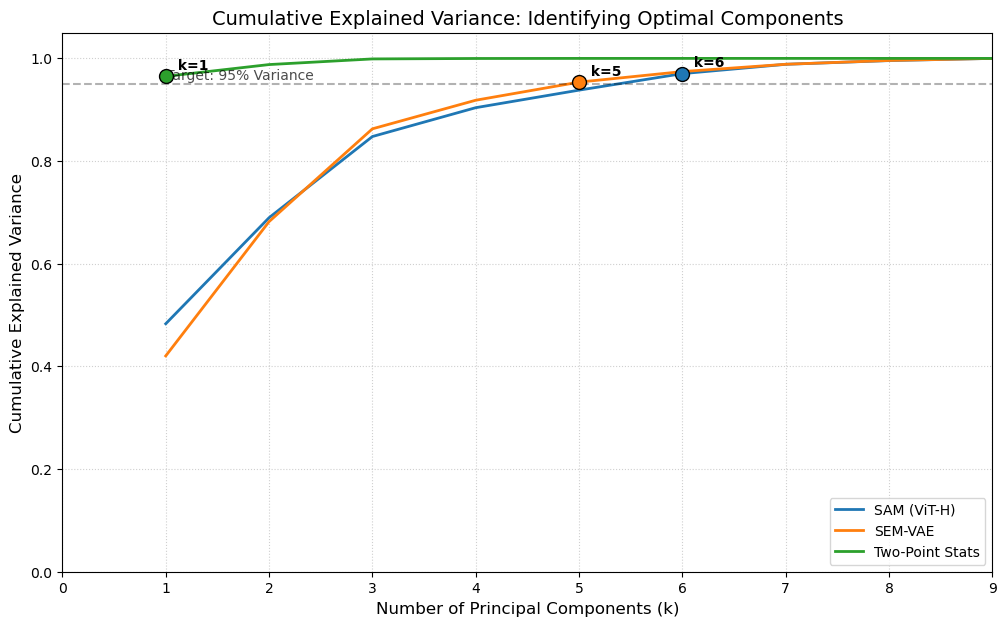


--- Summary: Components needed for equal variance ---
SAM (ViT-H): 6 components
SEM-VAE: 5 components
Two-Point Stats: 1 components


In [23]:
# ==========================================
# Variance Threshold Helper
# ==========================================

def get_target_k(cum_var, threshold=0.95):
    """Finds the first index where cumulative variance exceeds the threshold."""
    return np.argmax(cum_var >= threshold) + 1


# ==========================================
# Cumulative Explained Variance Analysis
# ==========================================

def plot_variance_with_intercepts(base_images, model_vae, device_vae, target_threshold=0.95, pad=False):
    print("Extracting features for all methods...")
    data_dict = {"base": base_images}

    # Feature extraction
    sam_feats = feature_extractor(data_dict, mode='sam')['base']
    vae_feats = feature_extractor(data_dict, mode='vae', model=model_vae, device=device_vae)['base']
    tp_feats = feature_extractor(data_dict, mode='tp', radial_bins=50, stats='all', pad=pad)['base']

    methods = {
        'SAM (ViT-H)': {'feats': sam_feats, 'color': '#1f77b4'},
        'SEM-VAE': {'feats': vae_feats, 'color': '#ff7f0e'},
        'Two-Point Stats': {'feats': tp_feats, 'color': '#2ca02c'}
    }

    plt.figure(figsize=(12, 7))

    results = {}

    for name, config in methods.items():
        # L2 normalization and standard scaling
        feats_l2 = normalize(config['feats'], axis=1)
        scaler = StandardScaler()
        feats_scaled = scaler.fit_transform(feats_l2)

        # Principal Component Analysis
        pca = PCA()
        pca.fit(feats_scaled)
        cum_var = np.cumsum(pca.explained_variance_ratio_)

        # Intercept calculation
        k_needed = get_target_k(cum_var, target_threshold)
        results[name] = k_needed

        # Cumulative variance curves
        x_axis = range(1, len(cum_var) + 1)
        plt.plot(x_axis, cum_var, label=f'{name}', color=config['color'], lw=2)

        # Intercept point and annotation
        plt.scatter(k_needed, cum_var[k_needed - 1], color=config['color'], s=100, edgecolors='black', zorder=5)
        plt.annotate(
            f' k={k_needed}',
            (k_needed, cum_var[k_needed - 1]),
            textcoords="offset points",
            xytext=(5, 5),
            ha='left',
            fontweight='bold'
        )

    # Plot formatting
    plt.axhline(y=target_threshold, color='black', linestyle='--', alpha=0.3)
    plt.text(1, target_threshold + 0.01, f'Target: {int(target_threshold * 100)}% Variance', color='black', alpha=0.7)

    plt.title('Cumulative Explained Variance: Identifying Optimal Components', fontsize=14)
    plt.xlabel('Number of Principal Components (k)', fontsize=12)
    plt.ylabel('Cumulative Explained Variance', fontsize=12)
    plt.ylim(0, 1.05)
    plt.xlim(0, max(results.values()) * 1.5)
    plt.legend(loc='lower right')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

    print("\n--- Summary: Components needed for equal variance ---")
    for name, k in results.items():
        print(f"{name}: {k} components")


# ==========================================
# Execution
# ==========================================

plot_variance_with_intercepts(subset_10_proc, model, device, target_threshold=0.95)

# 10. Procrustes Analysis

In [ ]:
# ==========================================
# Procrustes Analysis I/O
# ==========================================

def save_procrustes_results(procrustes_results, filename="Procrustes_Analysis_Results.pkl"):
    """
    Save Procrustes analysis results to disk.
    """
    with open(filename, "wb") as f:
        pickle.dump(procrustes_results, f)

    print(f"Results saved to: {filename}")


def load_procrustes_results(filename="Procrustes_Analysis_Results.pkl"):
    """
    Load previously saved Procrustes analysis results.
    """
    with open(filename, "rb") as f:
        procrustes_results = pickle.load(f)

    print(f"Results loaded from: {filename}")
    return procrustes_results


# ==========================================
# Procrustes Disparity Visualization
# ==========================================

def plot_procrustes_mean_std(procrustes_results, save_dir="procrustes_plots"):
    """
    Generates publication-quality Procrustes disparity curves with per-noise plots,
    a standalone shared legend, and a 2x2 multi-panel summary grid.
    """
    noise_types = ['gaussian', 'poisson', 'blur', 's&p']
    methods = ['tp', 'sam', 'vae']

    os.makedirs(save_dir, exist_ok=True)

    # Palette and marker mapping
    cmap = plt.get_cmap("tab10")
    method_colors = {
        'tp': cmap(0),
        'sam': cmap(1),
        'vae': cmap(2)
    }

    method_labels = {
        'tp': 'TP',
        'sam': 'SAM',
        'vae': 'VAE'
    }

    method_markers = {
        'sam': 'o',
        'vae': '^',
        'tp': 's'
    }

    # Global plot style configuration
    plt.rcParams.update({
        "font.size": 14,
        "axes.titlesize": 24,
        "axes.labelsize": 22,
        "legend.fontsize": 16,
        "xtick.labelsize": 20,
        "ytick.labelsize": 20,
        "lines.linewidth": 2.5,
        "axes.linewidth": 0.8
    })

    legend_handles = []
    legend_labels = []
    cached = {}

    # Individual noise plots
    for noise in noise_types:
        fig, ax = plt.subplots(figsize=(10, 6))
        cached[noise] = {}

        for method in methods:
            all_disparities = []
            ssims = None

            for run in procrustes_results:
                analysis = run[noise][method]
                run_ssims = np.array([r['ssim'] for r in analysis])
                run_disp = np.array([r['disparity'] for r in analysis])

                all_disparities.append(run_disp)
                if ssims is None:
                    ssims = run_ssims

            all_disparities = np.vstack(all_disparities)
            mean = all_disparities.mean(axis=0)
            std = all_disparities.std(axis=0)

            cached[noise][method] = (ssims, mean, std)

            color = method_colors[method]
            marker = method_markers[method]

            line, = ax.plot(
                ssims,
                mean,
                label=method_labels[method],
                color=color,
                marker=marker,
                markersize=9
            )

            ax.fill_between(
                ssims,
                mean - std,
                mean + std,
                color=color,
                alpha=0.2
            )

            if noise == noise_types[0]:
                legend_handles.append(line)
                legend_labels.append(method_labels[method])

        display_name = "Salt & Pepper" if noise == 's&p' else noise.capitalize()

        ax.invert_xaxis()
        ax.set_title(display_name)
        ax.set_xlabel("SSIM (Low Noise → High Noise)")
        ax.set_ylabel("Procrustes Disparity")
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.tick_params(axis='both', which='major', labelsize=20, width=2.0, length=8)
        ax.set_ylim(-0.05, 1.0)

        plt.tight_layout()

        filepath = os.path.join(save_dir, f"procrustes_{noise}_drift.png")
        plt.savefig(filepath, dpi=300, bbox_inches="tight")
        plt.close()

        print(f"Saved: {filepath}")

    # Standalone shared legend figure
    fig_leg = plt.figure(figsize=(10, 2))
    ax_leg = fig_leg.add_subplot(111)
    ax_leg.axis("off")

    ax_leg.legend(
        legend_handles,
        legend_labels,
        loc="center",
        ncol=3,
        frameon=False
    )

    legend_path = os.path.join(save_dir, "procrustes_legend.png")
    plt.savefig(legend_path, dpi=300, bbox_inches="tight")
    plt.close()

    print(f"Saved legend: {legend_path}")

    # Multi-panel summary grid (2x2)
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    grid_map = [
        ('gaussian', (0, 0)),
        ('poisson',  (0, 1)),
        ('blur',     (1, 0)),
        ('s&p',      (1, 1))
    ]

    for noise, (i, j) in grid_map:
        ax = axes[i, j]

        for method in methods:
            ssims, mean, std = cached[noise][method]
            color = method_colors[method]
            marker = method_markers[method]

            ax.plot(
                ssims,
                mean,
                color=color,
                marker=marker,
                markersize=9
            )

            ax.fill_between(
                ssims,
                mean - std,
                mean + std,
                color=color,
                alpha=0.2
            )

        ax.invert_xaxis()
        title = "Salt & Pepper" if noise == "s&p" else noise.capitalize()
        ax.set_title(title)
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.tick_params(axis='both', which='major', labelsize=18, width=2.5, length=12)
        ax.set_ylim(-0.1, 1.0)

        if i == 1:
            ax.set_xlabel("SSIM (Low Noise → High Noise)")
        if j == 0:
            ax.set_ylabel("Procrustes Disparity")

    plt.tight_layout()

    grid_path = os.path.join(save_dir, "procrustes_2x2_grid.png")
    plt.savefig(grid_path, dpi=300, bbox_inches="tight")
    plt.close()

    print(f"Saved grid: {grid_path}")


# ==========================================
# Procrustes Feature Alignment
# ==========================================

def run_fair_procrustes(all_features, k_dict, random_seed=42):
    """
    Performs Procrustes disparity analysis using method-specific PCA and standardization.
    """
    final_results = {}

    for method_name in ['sam', 'vae', 'tp']:
        print(f"Processing {method_name.upper()} | k={k_dict[method_name]}")

        method_feats = all_features[method_name]
        original_raw = method_feats["ssim_1.00"]

        # Standardize features (mean=0, variance=1)
        scaler = StandardScaler()
        orig_scaled = scaler.fit_transform(original_raw)

        # Fit PCA using method-specific component count
        k = k_dict[method_name]
        max_k = min(k, orig_scaled.shape[0] - 1)
        pca = PCA(n_components=max_k, random_state=random_seed)
        X_pca_original = pca.fit_transform(orig_scaled)

        method_analysis = []
        sorted_keys = sorted(method_feats.keys(), key=lambda x: float(x.split('_')[1]), reverse=True)

        # Project representations and compute Procrustes disparity
        for key in sorted_keys:
            target_ssim = float(key.split('_')[1])
            noisy_scaled = scaler.transform(method_feats[key])
            X_pca_noisy = pca.transform(noisy_scaled)

            _, _, disparity = procrustes(X_pca_original, X_pca_noisy)
            method_analysis.append({'ssim': target_ssim, 'disparity': disparity})

        final_results[method_name] = method_analysis

    return final_results


# ==========================================
# Multi-Method Procrustes Comparison
# ==========================================

def procrustes_compare_results_fair(subset, k_dict, dataset_floor, num_variations=10, model=None, device=None):
    """
    Orchestrates noise generation and comparative Procrustes analysis across methods.
    """
    noise_types = ['gaussian', 'poisson', 'blur', 's&p']
    run_results = {noise: {} for noise in noise_types}

    for noise in noise_types:
        print(f"\n    >>> Analyzing Noise Mode: {noise.upper()}")

        # Determine SSIM degradation range using dynamic floor for blur
        if noise == 'blur':
            current_range = (0.99, dataset_floor)
            print(f"        [Mode: Blur] Using dynamic floor range: 1.0 -> {dataset_floor}")
        else:
            current_range = (0.95, 0.05)
            print(f"        [Mode: {noise}] Using standard range: 0.95 -> 0.05")

        # Generate noisy variations
        variations = generate_noisy_batch_variations(
            subset, 
            noise_type=noise, 
            num_variations=num_variations, 
            ssim_range=current_range
        )

        # Feature extraction across all representations
        all_features = {
            'tp':  feature_extractor(variations, mode='tp', pad=False, radial_bins=50),
            'sam': feature_extractor(variations, mode='sam'),
            'vae': feature_extractor(variations, mode='vae', model=model, device=device)
        }

        # Procrustes analysis execution
        method_disparities = run_fair_procrustes(all_features, k_dict)
        run_results[noise] = method_disparities

    return run_results


# ==========================================
# Analysis Execution, Storage, and Plotting
# ==========================================

# Set optimal number of components identified from explained variance analysis
my_optimal_ks = {
    'sam': 6,
    'vae': 5,
    'tp': 2
}

procrustes_results = []
num_runs = 3

for i in range(num_runs):
    subset_10 = random.sample(subset_50_proc, k=10)

    analysis_run = procrustes_compare_results_fair(
        subset_10,
        k_dict=my_optimal_ks,
        dataset_floor=dataset_floor,
        num_variations=10,
        model=model,
        device=device
    )
    procrustes_results.append(analysis_run)

# Save results to disk
save_procrustes_results(procrustes_results)

# Default visualization upon analysis completion
plot_procrustes_mean_std(procrustes_results)

In [78]:
from sklearn.preprocessing import normalize

def run_fair_procrustes_with_l2(all_features, k_dict, random_seed=42):
    """
    Performs Procrustes using method-specific PCA/Scaling WITH L2 normalization.
    """
    final_results = {}

    for method_name in ['sam', 'vae', 'tp']:
        print(f"Processing {method_name.upper()} | k={k_dict[method_name]} (With L2)")

        method_feats = all_features[method_name]

        # 1. L2 Normalize then Standardize
        original_l2 = normalize(method_feats["ssim_1.00"], axis=1)
        scaler = StandardScaler()
        orig_scaled = scaler.fit_transform(original_l2)

        # 2. Fit PCA
        k = k_dict[method_name]
        max_k = min(k, orig_scaled.shape[0] - 1)
        pca = PCA(n_components=max_k, random_state=random_seed)
        X_pca_original = pca.fit_transform(orig_scaled)

        method_analysis = []
        sorted_keys = sorted(method_feats.keys(), key=lambda x: float(x.split('_')[1]), reverse=True)

        # 3. Project and Align
        for key in sorted_keys:
            target_ssim = float(key.split('_')[1])
            noisy_l2 = normalize(method_feats[key], axis=1) # Normalize current set
            noisy_scaled = scaler.transform(noisy_l2)
            X_pca_noisy = pca.transform(noisy_scaled)

            _, _, disparity = procrustes(X_pca_original, X_pca_noisy)
            method_analysis.append({'ssim': target_ssim, 'disparity': disparity})

        final_results[method_name] = method_analysis
    return final_results


--- STARTING RANDOM RUN 1 OF 3 ---

    >>> Analyzing Noise Mode: GAUSSIAN
        [Mode: gaussian] Using standard range: 0.95 -> 0.05


Normalizing Images:   0%|          | 0/10 [00:00<?, ?it/s]

Generating GAUSSIAN:   0%|          | 0/10 [00:00<?, ?it/s]

Processing batch:   0%|          | 0/10 [00:00<?, ?it/s]

Processing batch:   0%|          | 0/10 [00:00<?, ?it/s]

...

Processing batch:   0%|          | 0/10 [00:00<?, ?it/s]

Processing batch:   0%|          | 0/10 [00:00<?, ?it/s]

Processing batch:   0%|          | 0/10 [00:00<?, ?it/s]

Processing batch:   0%|          | 0/10 [00:00<?, ?it/s]

Extracting features for dataset: ssim_1.00 using mode: tp
Extracting features for dataset: ssim_0.95 using mode: tp
Extracting features for dataset: ssim_0.85 using mode: tp
Extracting features for dataset: ssim_0.75 using mode: tp
Extracting features for dataset: ssim_0.65 using mode: tp
Extracting features for dataset: ssim_0.55 using mode: tp
Extracting features for dataset: ssim_0.45 using mode: tp
Extracting features for dataset: ssim_0.35 using mode: tp
Extracting features for dataset: ssim_0.25 using mode: tp
Extracting features for dataset: ssim_0.15 using mode: tp
Extracting features for dataset: ssim_0.05 using mode: tp
Extracting features for dataset: ssim_1.00 using mode: sam
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 256, 64, 64])
Embedding shape used for pooling: torch.Size([1, 25

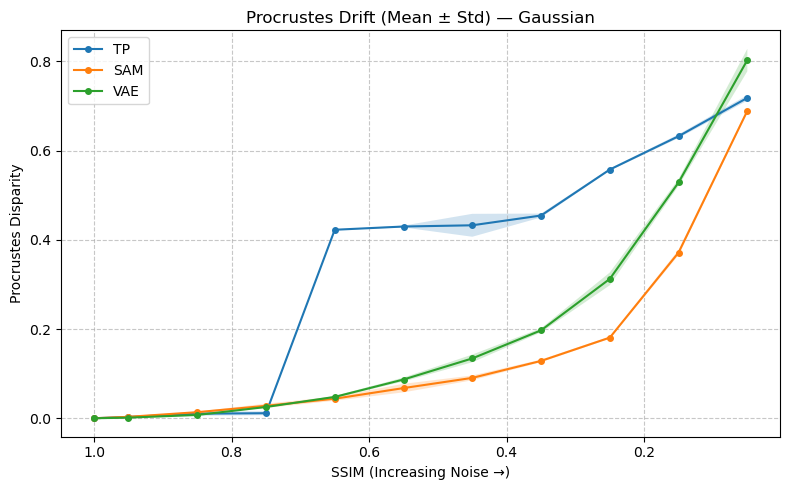

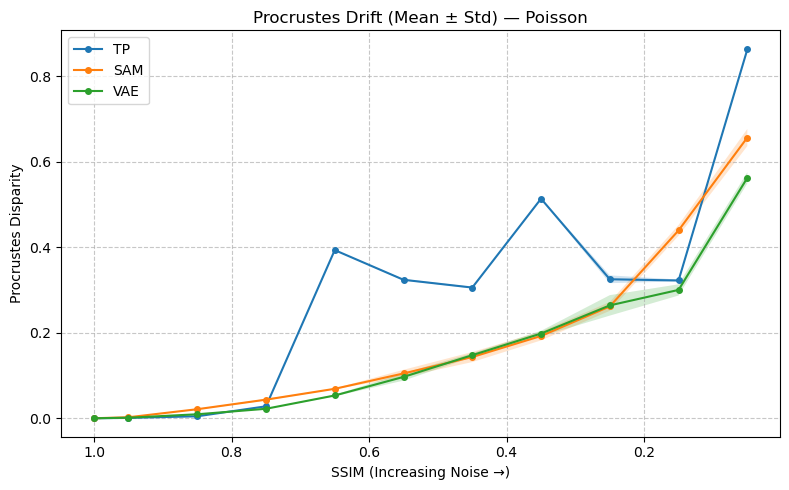

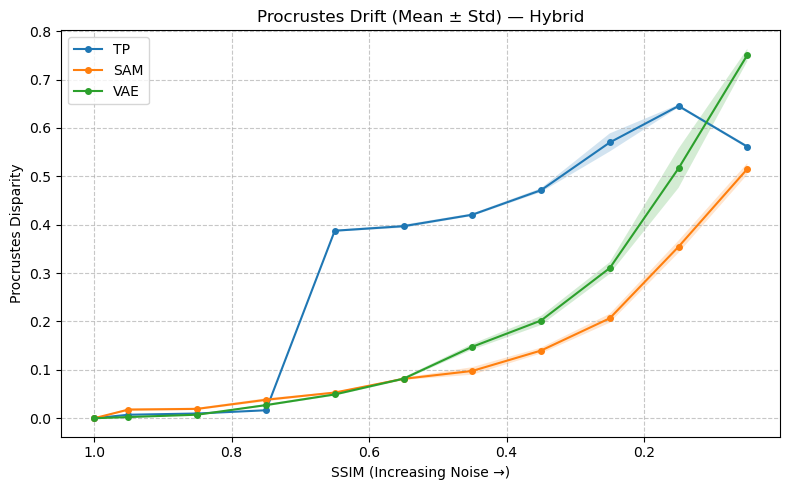

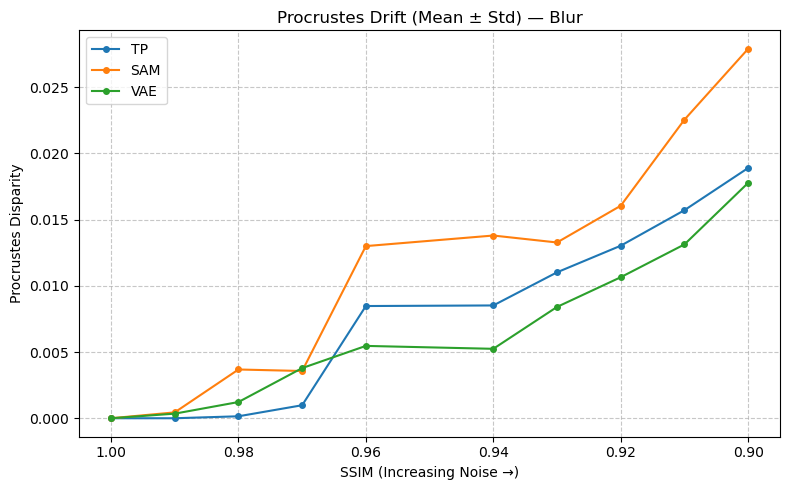

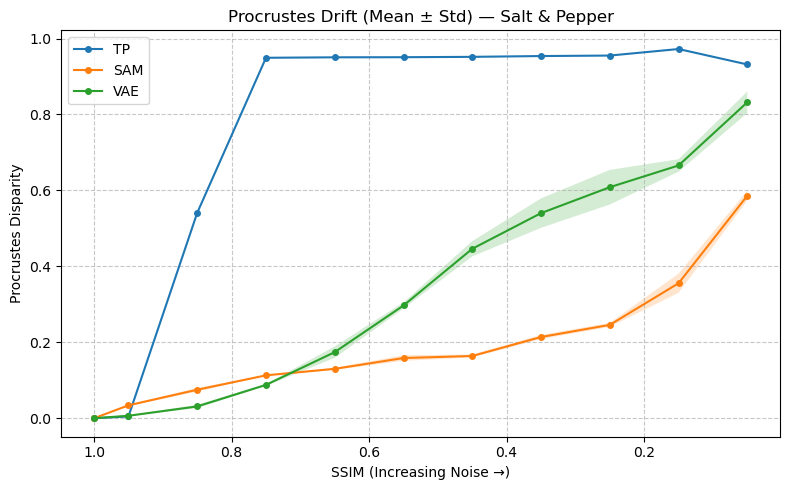

In [153]:
def procrustes_compare_results_fair(subset, k_dict, dataset_floor, use_l2=True, num_variations=10, model=None, device=None):
    """
    Orchestrates noise generation and fair procrustes analysis.
    ADAPTATION: Uses dataset_floor for 'blur' and standard range for others.
    """
    noise_types = ['gaussian', 'poisson', 'hybrid', 'blur', 's&p']
    run_results = {noise: {} for noise in noise_types}

    for noise in noise_types:
        print(f"\n    >>> Analyzing Noise Mode: {noise.upper()}")
        
        # 1. Determine the SSIM range for this specific mode (Mirroring No L2 logic)
        if noise == 'blur':
            # Range from 1.0 down to your calculated bottleneck
            current_range = (1.0, dataset_floor)
            print(f"        [Mode: Blur] Using dynamic floor range: 1.0 -> {dataset_floor}")
        else:
            # Default range for additive/stochastic noise
            current_range = (0.95, 0.05)
            print(f"        [Mode: {noise}] Using standard range: 0.95 -> 0.05")

        # 2. Generate noisy variations with per-image verification
        variations = generate_noisy_batch_variations(
            subset, 
            noise_type=noise, 
            num_variations=num_variations, 
            ssim_range=current_range
        )

        # 3. Extract features for all methods
        all_features = {
            'tp':  feature_extractor(variations, mode='tp', pad=False, radial_bins=50),
            'sam': feature_extractor(variations, mode='sam'),
            'vae': feature_extractor(variations, mode='vae', model=model, device=device)
        }

        # 4. Perform Fair Procrustes Analysis
        if use_l2:
            method_disparities = run_fair_procrustes_with_l2(all_features, k_dict)
        else:
            method_disparities = run_fair_procrustes_no_l2(all_features, k_dict)

        run_results[noise] = method_disparities

    return run_results

# --- EXECUTION BLOCK ---
my_optimal_ks = {
    'sam': 6,
    'vae': 5,
    'tp': 2
}

# Calculate the ssim floor once before the loop
# dataset_floor = find_dataset_ssim_floor(subset_50_proc)
dataset_floor = 0.90 

procrustes_results = []
num_runs = 3 

for i in range(num_runs):
    print(f"\n--- STARTING RANDOM RUN {i+1} OF {num_runs} ---")
    
    # Sample a random subset
    subset_10 = random.sample(subset_50_proc, k=min(10, len(subset_50_proc)))

    # CALL DIFFERENCE: use_l2 is now set to True
    analysis_run = procrustes_compare_results_fair(
        subset_10,
        k_dict=my_optimal_ks,
        dataset_floor=dataset_floor, 
        use_l2=True,
        num_variations=10,
        model=model,
        device=device
    )
    procrustes_results.append(analysis_run)

# Plot the 5 resulting graphs
plot_procrustes_mean_std(procrustes_results)

# 11. Single-Image Stability Analysis using Cosine Similarity and Euclidean Distance

In [ ]:
# ==========================================
# Single Image Stability Analysis
# ==========================================

def analyze_sis_with_self_check(
    images,
    num_steps,
    model,
    device,
    ssim_range=(0.95, 0.05),
    noise_floor=0.90,
    pad=False,
    radial_bins=50
):
    """
    Performs stability analysis across noise degradation levels and computes
    cosine similarity, Euclidean distance, and cosine distance across representations.
    """
    # Generate noisy image sets and collect SSIM axes
    noisy_img_sets = []
    all_ssim_axes = []

    for img in images:
        noisy_set, ssim_axes = generate_noise_degradation_set(
            img,
            num_steps=num_steps,
            ssim_range=ssim_range,
            noise_floor=noise_floor
        )
        noisy_img_sets.append(noisy_set)
        all_ssim_axes.append(ssim_axes)

    # Feature extraction across models and methods
    extracted_features = []
    for image_set in noisy_img_sets:
        image_set_features = {}
        for noise_type, type_images in image_set.items():
            image_set_features[noise_type] = {
                "tp": tp_stat_extractor(type_images, pad=pad, radial_bins=radial_bins),
                "SAM": sam_feature_extractor(type_images),
                "VAE": vae_latent_extractor(type_images, model, device)
            }
        extracted_features.append(image_set_features)

    # Similarity and distance calculations relative to original reference
    cosine_similarities = []
    euclidean_distances = []
    cosine_distances = []

    for image_set_features in extracted_features:
        cos_dict, euc_dict, cos_dist_dict = {}, {}, {}
        for noise_type, method_features in image_set_features.items():
            cos_dict[noise_type], euc_dict[noise_type], cos_dist_dict[noise_type] = {}, {}, {}
            for method_name, feats in method_features.items():
                feats = np.asarray(feats)
                original_vec = feats[0].reshape(1, -1)

                # Cosine similarity
                sims = cosine_similarity(feats, original_vec).flatten()

                # Normalized Euclidean distance
                feats_norm = normalize(feats, axis=1)
                dists = np.linalg.norm(feats_norm - feats_norm[0], axis=1)

                cos_dict[noise_type][method_name] = sims
                euc_dict[noise_type][method_name] = dists
                cos_dist_dict[noise_type][method_name] = 1.0 - sims

        cosine_similarities.append(cos_dict)
        euclidean_distances.append(euc_dict)
        cosine_distances.append(cos_dist_dict)

    # Aggregate means and standard deviations across samples
    noise_types = list(cosine_similarities[0].keys())
    methods = list(cosine_similarities[0][noise_types[0]].keys())
    steps = num_steps + 1

    avg_cos = {nt: {m: np.zeros(steps) for m in methods} for nt in noise_types}
    std_cos = {nt: {m: np.zeros(steps) for m in methods} for nt in noise_types}
    avg_euc = {nt: {m: np.zeros(steps) for m in methods} for nt in noise_types}
    std_euc = {nt: {m: np.zeros(steps) for m in methods} for nt in noise_types}

    avg_ssim_axes = {nt: np.mean([ax[nt] for ax in all_ssim_axes], axis=0) for nt in noise_types}

    for nt in noise_types:
        for m in methods:
            c_vals = np.array([img[nt][m] for img in cosine_similarities])
            e_vals = np.array([img[nt][m] for img in euclidean_distances])

            avg_cos[nt][m] = np.mean(c_vals, axis=0)
            std_cos[nt][m] = np.std(c_vals, axis=0)
            avg_euc[nt][m] = np.mean(e_vals, axis=0)
            std_euc[nt][m] = np.std(e_vals, axis=0)

    return {
        "avg_cosine": avg_cos,
        "std_cosine": std_cos,
        "avg_euclidean": avg_euc,
        "std_euclidean": std_euc,
        "ssim_axes": avg_ssim_axes,
        "raw_features": extracted_features
    }


# ==========================================
# Results Storage and Retrieval
# ==========================================

def save_sis_results(results, filename="sis_results_full_analysis.pkl"):
    """
    Save stability analysis results to disk.
    """
    with open(filename, "wb") as f:
        pickle.dump(results, f)
    print(f"Results saved to: {filename}")


def load_sis_results(filename="sis_results_full_analysis.pkl"):
    """
    Load stability analysis results from disk.
    """
    with open(filename, "rb") as f:
        results = pickle.load(f)
    print(f"Results loaded from: {filename}")
    return results


# ==========================================
# Tabular Statistical Summary
# ==========================================

def print_results_table(sis_results):
    """
    Displays formatted summary tables of cosine similarity across all noise modes.
    """
    avg_data = sis_results['avg_cosine']
    std_data = sis_results['std_cosine']

    print(f"\n{'=' * 85}")
    print("STATISTICAL SUMMARY: COSINE SIMILARITY")
    print(f"{'=' * 85}")

    for mode in avg_data.keys():
        display_mode = "SALT & PEPPER" if mode == 's&p' else mode.upper()
        print(f"\n>> Noise Mode: {display_mode}")

        mode_ssim_axis = np.asarray(sis_results['ssim_axes'][mode])
        table_data = {"Target SSIM": [f"{s:.2f}" for s in mode_ssim_axis]}

        for method in avg_data[mode].keys():
            means = np.asarray(avg_data[mode][method])
            stds = np.asarray(std_data[mode][method])
            table_data[method.upper()] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(means, stds)]

        df = pd.DataFrame(table_data)
        print(df.to_string(index=False))
        print("-" * 65)


# ==========================================
# Single Image Stability (SIS) Visualization
# ==========================================

def plot_sis(
    sis_results,
    metric_name="avg_cosine",
    noise_types=("gaussian", "poisson", "blur", "s&p"),
    methods=("tp", "SAM", "VAE"),
    save_dir="Single_Image_Stability"
):
    """
    Generates Single Image Stability (SIS) plots: individual degradation curves,
    a shared legend, and a 2x2 multi-panel grid. Displays plots in the notebook
    and saves high-resolution figures to disk.
    """
    os.makedirs(save_dir, exist_ok=True)

    avg_data = sis_results[metric_name]
    std_data = sis_results["std_" + metric_name.split("avg_")[1]]

    # Color palette and marker mapping
    cmap = plt.get_cmap("tab10")
    colors = {
        "tp": cmap(0),
        "SAM": cmap(1),
        "VAE": cmap(2)
    }

    label_map = {
        "tp": "2PTS",
        "SAM": "SAM",
        "VAE": "VAE"
    }

    method_markers = {
        "SAM": "o",
        "VAE": "^",
        "tp": "s"
    }

    # Style configuration
    plt.rcParams.update({
        "font.size": 14,
        "axes.titlesize": 24,
        "axes.labelsize": 22,
        "legend.fontsize": 16,
        "xtick.labelsize": 20,
        "ytick.labelsize": 20,
        "lines.linewidth": 2.5,
        "axes.linewidth": 0.8
    })

    # Reference SSIM evaluation axes
    target_axes = {
        "gaussian": np.linspace(0.95, 0.05, 10),
        "poisson": np.linspace(0.95, 0.05, 10),
        "s&p": np.linspace(0.95, 0.05, 10),
        "blur": np.linspace(0.99, 0.90, 10),
        "hybrid": np.linspace(0.95, 0.05, 10),
    }

    full_axes = {
        noise: np.concatenate([[1.00], axis])
        for noise, axis in target_axes.items()
    }

    legend_handles = []
    legend_labels = []
    cached = {}

    # Individual noise mode plots
    for noise in noise_types:
        fig, ax = plt.subplots(figsize=(10, 6))
        cached[noise] = {}

        x = np.asarray(full_axes[noise])

        for method in methods:
            y = np.asarray(avg_data[noise][method]).flatten()
            yerr = np.asarray(std_data[noise][method]).flatten()

            if len(y) != len(x):
                raise ValueError(f"{noise}-{method}: expected {len(x)} points, got {len(y)}")

            color = colors[method]
            marker = method_markers[method]

            line, = ax.plot(
                x,
                y,
                color=color,
                marker=marker,
                markersize=9,
                label=label_map[method]
            )

            # Bound standard deviation envelopes within [0.00, 1.00]
            y_lower = np.clip(y - yerr, a_min=0.00, a_max=1.00)
            y_upper = np.clip(y + yerr, a_min=0.00, a_max=1.00)

            ax.fill_between(
                x,
                y_lower,
                y_upper,
                alpha=0.20,
                color=color
            )

            cached[noise][method] = (x, y, y_lower, y_upper)

            if noise == noise_types[0]:
                legend_handles.append(line)
                legend_labels.append(label_map[method])

        display_name = "Salt & Pepper" if noise.lower() == "s&p" else noise.capitalize()

        ax.set_title(display_name)
        ax.set_xlabel("SSIM (High → Low Noise)")
        ax.set_ylabel("Cosine Similarity")
        ax.invert_xaxis()
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.tick_params(axis='both', which='major', labelsize=20, width=2.0, length=8)

        if noise != "blur":
            ax.set_ylim(-0.1, 1.1)

        plt.tight_layout()

        filepath = os.path.join(save_dir, f"{display_name} Single Image Stability.png")
        plt.savefig(filepath, dpi=300, bbox_inches="tight")
        print(f"Saved: {filepath}")
        plt.show()
        plt.close()

    # Shared standalone legend figure
    fig_leg = plt.figure(figsize=(10, 2))
    ax_leg = fig_leg.add_subplot(111)
    ax_leg.axis("off")

    ax_leg.legend(
        legend_handles,
        legend_labels,
        loc="center",
        ncol=3,
        frameon=False
    )

    legend_path = os.path.join(save_dir, "sis_legend.png")
    plt.savefig(legend_path, dpi=300, bbox_inches="tight")
    print(f"Saved legend: {legend_path}")
    plt.show()
    plt.close()

    # Multi-panel summary grid (2x2)
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    grid_map = [
        ('gaussian', (0, 0)),
        ('poisson',  (0, 1)),
        ('blur',     (1, 0)),
        ('s&p',      (1, 1))
    ]

    for noise, (i, j) in grid_map:
        ax = axes[i, j]

        for method in methods:
            x, y, y_lower, y_upper = cached[noise][method]
            marker = method_markers[method]

            ax.plot(
                x,
                y,
                color=colors[method],
                marker=marker,
                markersize=9
            )

            ax.fill_between(
                x,
                y_lower,
                y_upper,
                color=colors[method],
                alpha=0.2
            )

        title = "Salt & Pepper" if noise == "s&p" else noise.capitalize()
        ax.set_title(title)
        ax.invert_xaxis()
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.tick_params(axis='both', which='major', labelsize=18, width=2.5, length=12)

        if noise != "blur":
            ax.set_ylim(-0.1, 1.1)

        if i == 1:
            ax.set_xlabel("SSIM (Low → High Noise)")
        if j == 0:
            ax.set_ylabel("Cosine Similarity")

    plt.tight_layout()

    grid_path = os.path.join(save_dir, "sis_2x2_grid.png")
    plt.savefig(grid_path, dpi=300, bbox_inches="tight")
    print(f"Saved grid: {grid_path}")
    plt.show()
    plt.close()


# ==========================================
# Execution Pipeline
# ==========================================

# Run analysis
sis_results = analyze_sis_with_self_check(
    subset_25_proc,
    num_steps=10,
    model=model,
    device=device,
    ssim_range=(0.95, 0.05),
    noise_floor=dataset_floor
)

# Verification of analyzed modes and bounds
detected_noise_modes = list(sis_results['avg_cosine'].keys())
print(f"Successfully analyzed noise modes: {detected_noise_modes}")
print(f"Blur Range: {sis_results['ssim_axes']['blur'][0]:.2f} to {sis_results['ssim_axes']['blur'][-1]:.2f}")
print(f"Poisson Range: {sis_results['ssim_axes']['poisson'][0]:.2f} to {sis_results['ssim_axes']['poisson'][-1]:.2f}")

# Save results
save_sis_results(sis_results, filename="sis_results_full_analysis.pkl")

# Statistical table output
print_results_table(sis_results)

# Generate and display SIS visual plots
plot_sis(sis_results, metric_name="avg_cosine")